# MELD: Clasificación de emociones por texto con Prompt Engineering (LLM + Few‑shot)

Este notebook resuelve **MELD** (Emotion Recognition in Conversations) como un problema de **clasificación de emociones** a partir de texto.
La idea principal es **no entrenar** un clasificador, sino hacer *prompt engineering* sobre un **modelo LLM instruct** y mejorar resultados con:

- **Prompt “estricto”** (etiqueta única + definiciones)
- **Contexto conversacional** (ventana de turnos previos)
- **Few‑shot** (ejemplos dentro del prompt)




## 1) Instalación y setup



In [1]:
#Librerias necesarias
%pip -q install -U transformers accelerate bitsandbytes sentence-transformers scikit-learn pandas matplotlib kagglehub

import os, re, random
from pathlib import Path
import numpy as np
import pandas as pd

import torch
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Mejor rendimiento en Ampere+ (si tu GPU soporta bfloat16)
DTYPE = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else torch.float16
print("CUDA:", torch.cuda.is_available(), "| dtype:", DTYPE)



[notice] A new release of pip is available: 25.1.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
CUDA: True | dtype: torch.bfloat16


## 2) Descargar / cargar MELD

Usamos `kagglehub` para descargar o cargar el dataset de meld.


In [2]:
import kagglehub

# Descarga (requiere que Kaggle esté configurado en tu entorno; en Colab suele ser necesario subir kaggle.json)
DATA_DIR = kagglehub.dataset_download("zaber666/meld-dataset")
DATA_DIR = Path(DATA_DIR)
print("Dataset en:", DATA_DIR)

# Buscar archivos esperados (por si cambian subcarpetas)
def find_one(pattern: str) -> Path:
    hits = list(DATA_DIR.glob(pattern))
    if len(hits) == 0:
        hits = list(DATA_DIR.glob("**/" + pattern))
    if len(hits) == 0:
        raise FileNotFoundError(f"No encuentro {pattern} dentro de {DATA_DIR}")
    return hits[0]

train_path = find_one("train_sent_emo.csv")
dev_path   = find_one("dev_sent_emo.csv")
test_path  = find_one("test_sent_emo.csv")

print("train:", train_path)
print("dev  :", dev_path)
print("test :", test_path)

train_raw = pd.read_csv(train_path, encoding="utf-8")
dev_raw   = pd.read_csv(dev_path, encoding="utf-8")
test_raw  = pd.read_csv(test_path, encoding="utf-8")

train_raw.head()


C:\Users\Haojie\Desktop\MacOS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset en: C:\Users\Haojie\.cache\kagglehub\datasets\zaber666\meld-dataset\versions\1
train: C:\Users\Haojie\.cache\kagglehub\datasets\zaber666\meld-dataset\versions\1\MELD-RAW\MELD.Raw\train\train_sent_emo.csv
dev  : C:\Users\Haojie\.cache\kagglehub\datasets\zaber666\meld-dataset\versions\1\MELD-RAW\MELD.Raw\dev_sent_emo.csv
test : C:\Users\Haojie\.cache\kagglehub\datasets\zaber666\meld-dataset\versions\1\MELD-RAW\MELD.Raw\test_sent_emo.csv


,Sr No.,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime
0,1,also I was the point person on my companys tr...,Chandler,neutral,neutral,0,0,8,21,"00:16:16,059","00:16:21,731"
1,2,You mustve had your hands full.,The Interviewer,neutral,neutral,0,1,8,21,"00:16:21,940","00:16:23,442"
2,3,That I did. That I did.,Chandler,neutral,neutral,0,2,8,21,"00:16:23,442","00:16:26,389"
3,4,So lets talk a little bit about your duties.,The Interviewer,neutral,neutral,0,3,8,21,"00:16:26,820","00:16:29,572"
4,5,My duties? All right.,Chandler,surprise,positive,0,4,8,21,"00:16:34,452","00:16:40,917"


## 3) Preprocesado: contexto conversacional + normalización de hablantes

MELD tiene `Dialogue_ID`, `Utterance_ID`, `Speaker`, `Utterance` y `Emotion`.  
Creamos una ventana de *N* turnos previos como contexto (por defecto `WINDOW=2`) y normalizamos hablantes por diálogo (`SPEAKER_0`, `SPEAKER_1`…).


In [3]:
# Parámetros de contexto
WINDOW = 2  # nº de turnos previos a incluir
MAX_CONTEXT_CHARS = 900  # recorta contexto largo para no inflar el prompt

def clean_text(s: str) -> str:
    if not isinstance(s, str):
        return ""
    # algunos dumps llevan apóstrofo raro 0x92
    s = s.replace("\x92", "'")
    s = re.sub(r"\s+", " ", s).strip()
    return s

def normalize_speakers(df: pd.DataFrame) -> pd.DataFrame:
    # Mapea Speaker -> SPEAKER_k dentro de cada Dialogue_ID
    df = df.copy()
    df["Speaker"] = df["Speaker"].astype(str).map(clean_text)
    norm = []
    for _, g in df.groupby("Dialogue_ID", sort=False):
        speakers = {}
        next_id = 0
        for spk in g["Speaker"].tolist():
            if spk not in speakers:
                speakers[spk] = f"SPEAKER_{next_id}"
                next_id += 1
        norm.extend([speakers[spk] for spk in g["Speaker"].tolist()])
    df["Speaker_N"] = norm
    return df

def build_context_rows(df: pd.DataFrame, split_name: str) -> pd.DataFrame:
    df = df.copy()
    df["split"] = split_name
    # Kaggle MELD suele traer: Dialogue_ID, Utterance_ID, Speaker, Utterance, Emotion, Sentiment
    for col in ["Dialogue_ID", "Utterance_ID", "Speaker", "Utterance", "Emotion"]:
        if col not in df.columns:
            raise KeyError(f"Falta columna {col}. Columnas disponibles: {df.columns.tolist()}")
    df["Utterance"] = df["Utterance"].map(clean_text)
    df["Emotion"] = df["Emotion"].astype(str).map(lambda x: clean_text(x).lower())

    df = df.sort_values(["Dialogue_ID", "Utterance_ID"]).reset_index(drop=True)
    df = normalize_speakers(df)

    # construir contexto
    contexts = []
    current_turns = []
    for _, g in df.groupby("Dialogue_ID", sort=False):
        utts = g["Utterance"].tolist()
        spks = g["Speaker_N"].tolist()
        for i in range(len(g)):
            start = max(0, i - WINDOW)
            ctx_lines = [f"{spks[j]}: {utts[j]}" for j in range(start, i)]
            ctx = "\n".join(ctx_lines).strip()
            if len(ctx) > MAX_CONTEXT_CHARS:
                ctx = ctx[-MAX_CONTEXT_CHARS:]  # recorte por la izquierda
            contexts.append(ctx)
            current_turns.append(f"{spks[i]}: {utts[i]}")

    df_out = pd.DataFrame({
        "split": df["split"].values,
        "dialogue_id": df["Dialogue_ID"].values,
        "utterance_id": df["Utterance_ID"].values,
        "speaker": df["Speaker_N"].values,
        "utterance": df["Utterance"].values,
        "emotion": df["Emotion"].values,
        "context": contexts,
        "current_turn": current_turns
    })
    return df_out

train_df = build_context_rows(train_raw, "train")
dev_df   = build_context_rows(dev_raw, "dev")
test_df  = build_context_rows(test_raw, "test")

print("train/dev/test:", len(train_df), len(dev_df), len(test_df))
train_df.head()


train/dev/test: 9989 1109 2610


,split,dialogue_id,utterance_id,speaker,utterance,emotion,context,current_turn
0,train,0,0,SPEAKER_0,also I was the point person on my company's tr...,neutral,,SPEAKER_0: also I was the point person on my c...
1,train,0,1,SPEAKER_1,You must've had your hands full.,neutral,SPEAKER_0: also I was the point person on my c...,SPEAKER_1: You must've had your hands full.
2,train,0,2,SPEAKER_0,That I did. That I did.,neutral,SPEAKER_0: also I was the point person on my c...,SPEAKER_0: That I did. That I did.
3,train,0,3,SPEAKER_1,So let's talk a little bit about your duties.,neutral,SPEAKER_1: You must've had your hands full.\nS...,SPEAKER_1: So let's talk a little bit about yo...
4,train,0,4,SPEAKER_0,My duties? All right.,surprise,SPEAKER_0: That I did. That I did.\nSPEAKER_1:...,SPEAKER_0: My duties? All right.


## 4) Labels y validación rápida de clases

MELD voy a aplicar estas 7 emociones:
`anger, disgust, fear, joy, neutral, sadness, surprise`


In [4]:
LABELS = ["anger", "disgust", "fear", "joy", "neutral", "sadness", "surprise"]

all_labels = sorted(set(train_df["emotion"]) | set(dev_df["emotion"]) | set(test_df["emotion"]))
print("Etiquetas encontradas:", all_labels)

unknown = [x for x in all_labels if x not in LABELS]
if unknown:
    print("Etiquetas no esperadas:", unknown)

train_df["emotion"].value_counts()


Etiquetas encontradas: ['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']


emotion
neutral     4710
joy         1743
surprise    1205
anger       1109
sadness      683
disgust      271
fear         268
Name: count, dtype: int64

## 5) Cargar un LLM instruct (7B/8B) en 4‑bit

Recomendados (buenos para clasificación por prompt):
- `mistralai/Mistral-7B-Instruct-v0.3`
- `meta-llama/Meta-Llama-3.1-8B-Instruct` (requiere aceptar licencia en HF)
- `Qwen/Qwen2.5-7B-Instruct` (suele ir muy bien)



In [5]:
from transformers import AutoTokenizer, AutoModelForCausalLM, GenerationConfig

MODEL_NAME = "meta-llama/Meta-Llama-3.1-8B-Instruct"

# Carga 4-bit (bitsandbytes)
bnb_config = dict(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=DTYPE,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    device_map="auto",
    torch_dtype=DTYPE,
    **bnb_config,
)

# Configuración de generación (clasificación -> respuesta corta, determinista)
gen_cfg = GenerationConfig(
    max_new_tokens=8,
    do_sample=False,
    temperature=0.0,
    top_p=1.0,
    repetition_penalty=1.0,
)

print("Modelo cargado en:", next(model.parameters()).device)


`torch_dtype` is deprecated! Use `dtype` instead!
The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.
Loading checkpoint shards: 100%|██████████| 4/4 [00:21<00:00,  5.50s/it]
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Modelo cargado en: cuda:0


## 6) Prompt base

Clave para mejorar:
- pedir **una sola etiqueta** y **nada más**
- dar **definiciones** breves de cada emoción
- instrucción de desempate: si hay duda -> `neutral`


In [12]:
EMOTION_DEFS = {
    "anger":    "anger, irritation, frustration, hostility",
    "disgust":  "disgust, repulsion, strong rejection",
    "fear":     "fear, anxiety, intense worry, feeling threatened",
    "joy":      "joy, enthusiasm, satisfaction, positive humor",
    "neutral":  "no strong emotion, informational/normal tone",
    "sadness":  "sadness, sorrow, disappointment, discouragement",
    "surprise": "surprise, shock, disbelief, unexpected reaction",
}

SYSTEM_PROMPT = (
    "You are an emotion classifier for dialogue turns.\n"
    "You must choose EXACTLY ONE label from the list and output ONLY the label.\n"
    f"Labels: {', '.join(LABELS)}.\n\n"
    "Quick definitions:\n" +
    "\n".join([f"- {k}: {v}" for k, v in EMOTION_DEFS.items()]) +
    "\n\nRule: if it is not clear, answer 'neutral'."
)

def build_user_prompt(context: str, current_turn: str) -> str:
    context = (context or "").strip()
    if context:
        return (
            "Previous context:\n"
            f"{context}\n\n"
            "Current turn:\n"
            f"{current_turn}\n\n"
            "What is the emotion of the current turn? Answer ONLY with the label."
        )
    else:
        return (
            "Current turn:\n"
            f"{current_turn}\n\n"
            "What is the emotion of the current turn? Answer ONLY with the label."
        )

def make_chat_input(system_prompt: str, user_prompt: str) -> str:
    # Use the chat template if supported; otherwise fall back to plain text
    if hasattr(tokenizer, "apply_chat_template") and getattr(tokenizer, "chat_template", None):
        messages = [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt},
        ]
        return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return f"[SYSTEM]\n{system_prompt}\n\n[USER]\n{user_prompt}\n\n[ASSISTANT]\n"

LABEL_RE = re.compile(r"(anger|disgust|fear|joy|neutral|sadness|surprise)", re.IGNORECASE)

def parse_label(text: str) -> str:
    t = (text or "").strip().lower()
    t = re.sub(r"[^a-z\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    m = LABEL_RE.search(t)
    if m:
        return m.group(1).lower()
    return "neutral"

@torch.inference_mode()
def predict_one(context: str, current_turn: str) -> str:
    user_prompt = build_user_prompt(context, current_turn)
    prompt = make_chat_input(SYSTEM_PROMPT, user_prompt)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, generation_config=gen_cfg)
    gen = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return parse_label(gen)

# sanity check
row = dev_df.sample(1, random_state=SEED).iloc[0]
print("GT:", row["emotion"])
print("Pred:", predict_one(row["context"], row["current_turn"]))
print("\nTurn:\n", row["current_turn"])
print("\nContext:\n", row["context"])


Setting `pad_token_id` to `eos_token_id`:128001 for open-end generation.


GT: neutral
Pred: neutral

Turn:
 SPEAKER_2: Hi, sorry I'm late, I couldn't find my bearings.

Context:
 SPEAKER_1: Mom already called this morning to remind me not to wear my hair up. Did you know my ears are not my best feature?
SPEAKER_0: Some days it's all I can think about.


## 7) Evaluación (rápida) en un subconjunto

Ajusta `EVAL_N_DEV` y `EVAL_N_TEST` según tiempo.


In [13]:
from tqdm.auto import tqdm

EVAL_N_DEV  = 600   # para probar prompts rápido
EVAL_N_TEST = 1200   # evaluación más seria

def eval_df(df: pd.DataFrame, n: int, title: str):
    sub = df.sample(n=min(n, len(df)), random_state=SEED).reset_index(drop=True)
    y_true = sub["emotion"].tolist()
    y_pred = []
    for _, r in tqdm(sub.iterrows(), total=len(sub), desc=title):
        y_pred.append(predict_one(r["context"], r["current_turn"]))
    print("accuracy:", accuracy_score(y_true, y_pred))
    print("macro f1:", f1_score(y_true, y_pred, average="macro"))
    print("weighted f1:", f1_score(y_true, y_pred, average="weighted"))
    print("\n", classification_report(y_true, y_pred, labels=LABELS, zero_division=0))
    return y_true, y_pred

y_true_dev, y_pred_dev = eval_df(dev_df, EVAL_N_DEV, "DEV baseline")


DEV baseline: 100%|██████████| 600/600 [04:45<00:00,  2.11it/s]

accuracy: 0.5966666666666667
macro f1: 0.531188607075986
weighted f1: 0.5974023338690363

               precision    recall  f1-score   support

       anger       0.45      0.73      0.56        78
     disgust       0.55      0.38      0.44        16
        fear       0.70      0.33      0.45        21
         joy       0.53      0.44      0.48        88
     neutral       0.74      0.68      0.71       253
     sadness       0.58      0.54      0.56        65
    surprise       0.49      0.54      0.52        79

    accuracy                           0.60       600
   macro avg       0.58      0.52      0.53       600
weighted avg       0.62      0.60      0.60       600



### Matriz de confusión (DEV)

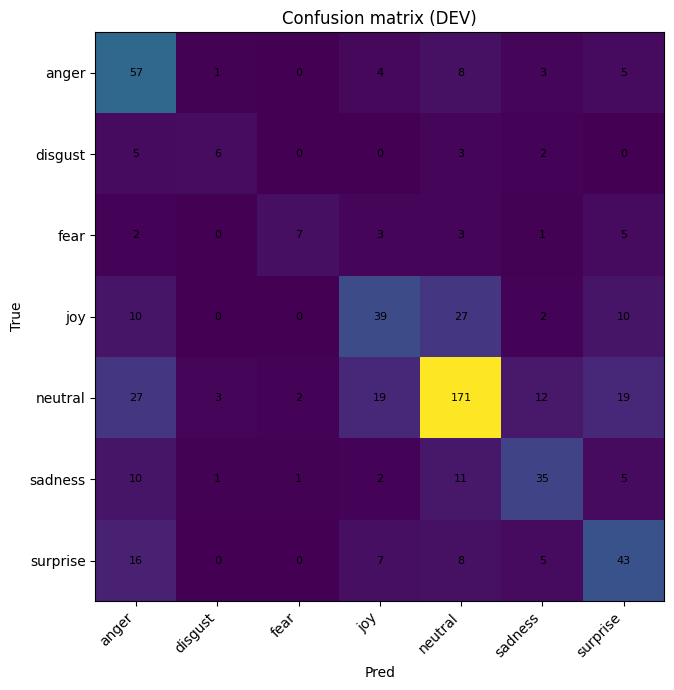

In [14]:
cm = confusion_matrix(y_true_dev, y_pred_dev, labels=LABELS)

plt.figure(figsize=(7, 7))
plt.imshow(cm)
plt.xticks(range(len(LABELS)), LABELS, rotation=45, ha="right")
plt.yticks(range(len(LABELS)), LABELS)
plt.title("Confusion matrix (DEV)")
plt.xlabel("Pred")
plt.ylabel("True")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()


## 8) Visualización: grafo dirigido de emociones entre hablantes (GIF)

Esta sección crea un **GIF animado** donde cada frame actualiza la emoción del hablante **hacia** la otra persona
(asumimos como *target* el hablante del turno anterior; puedes cambiarlo si tienes reglas mejores).

**Entrada:** un diálogo (por `dialogue_id`) de `dev_df` / `test_df` / `train_df`.  
**Salida:** archivo `emotion_graph.gif` y previsualización en notebook.


In [15]:
# Si no tienes estas librerías instaladas:
%pip -q install -U networkx imageio pillow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import math
import numpy as np
import networkx as nx
import imageio.v2 as imageio
import matplotlib.pyplot as plt
from IPython.display import Image, display
from pathlib import Path

# Colores por emoción (ajústalos si quieres)
EMO_COLOR = {
    "anger":   "#d62728",
    "disgust": "#2ca02c",
    "fear":    "#9467bd",
    "joy":     "#ff7f0e",
    "neutral": "#7f7f7f",
    "sadness": "#1f77b4",
    "surprise":"#bcbd22",
}

def _fixed_layout(nodes):
    """Layout estable (círculo) para que la animación no 'salte'."""
    n = len(nodes)
    if n == 1:
        return {nodes[0]: (0.0, 0.0)}
    pos = {}
    for i, node in enumerate(nodes):
        ang = 2 * math.pi * i / n
        pos[node] = (math.cos(ang), math.sin(ang))
    return pos

def draw_graph_frame(state_edges, nodes, step_title="", highlight_edge=None, figsize=(5.5, 5.5)):
    """
    state_edges: dict[(u,v)] -> emotion (última emoción conocida u->v)
    nodes: list[str]
    highlight_edge: (u,v) para resaltar la arista del turno actual
    """
    G = nx.DiGraph()
    G.add_nodes_from(nodes)
    for (u, v), emo in state_edges.items():
        if u != v:
            G.add_edge(u, v, emotion=emo)

    pos = _fixed_layout(nodes)

    fig = plt.figure(figsize=figsize, dpi=150)
    ax = plt.gca()
    ax.set_title(step_title, fontsize=10)
    ax.axis("off")

    # Nodes
    nx.draw_networkx_nodes(G, pos, node_size=1500, linewidths=1.5, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold", ax=ax)

    # Edges
    edge_list = list(G.edges())
    edge_colors = []
    edge_widths = []
    for (u, v) in edge_list:
        emo = G.edges[u, v].get("emotion", "neutral")
        edge_colors.append(EMO_COLOR.get(emo, "#7f7f7f"))
        edge_widths.append(2.8 if highlight_edge == (u, v) else 1.6)

    nx.draw_networkx_edges(
        G, pos,
        edgelist=edge_list,
        width=edge_widths,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=20,
        edge_color=edge_colors,
        connectionstyle="arc3,rad=0.15",  # separa A->B de B->A
        ax=ax
    )

    # Edge labels
    edge_labels = {(u, v): G.edges[u, v].get("emotion", "neutral") for (u, v) in edge_list}
    nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels=edge_labels,
        font_size=8,
        label_pos=0.55,
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
        rotate=False,
        ax=ax
    )

    fig.canvas.draw()

    # Matplotlib nuevo: usa buffer_rgba() (H, W, 4)
    buf = np.asarray(fig.canvas.buffer_rgba())
    img = buf[..., :3].copy()  # quitar alpha y copiar a array normal (H, W, 3)

    plt.close(fig)
    return img

def build_dialogue_rows(df, dialogue_id, infer_target_from_prev=True, default_target="OTHER"):
    """
    Devuelve una lista de dicts: speaker, target, text, context, current_turn, true_emotion
    """
    d = df[df["dialogue_id"] == dialogue_id].sort_values("utterance_id").reset_index(drop=True)
    rows = []
    prev_speaker = None
    for _, r in d.iterrows():
        speaker = r["speaker"]
        text = r["utterance"]
        target = default_target
        if infer_target_from_prev and prev_speaker is not None and prev_speaker != speaker:
            target = prev_speaker
        rows.append({
            "speaker": speaker,
            "target": target,
            "text": text,
            "context": r["context"],
            "current_turn": r["current_turn"],
            "true_emotion": r.get("emotion", None),
        })
        prev_speaker = speaker
    return rows

def classify_dialogue_rows(rows):
    """Añade pred_emotion usando predict_one(context, current_turn)."""
    out = []
    for r in rows:
        pred = predict_one(r["context"], r["current_turn"])
        out.append({**r, "pred_emotion": pred})
    return out

def dialogue_to_gif(classified_rows, out_gif_path="emotion_graph.gif", fps=1):
    """Genera GIF animando la emoción (última) en cada arista speaker->target."""
    nodes = sorted(set([r["speaker"] for r in classified_rows] + [r["target"] for r in classified_rows]))
    state_edges = {}
    frames = []
    for i, r in enumerate(classified_rows, start=1):
        u, v, emo = r["speaker"], r["target"], r["pred_emotion"]
        state_edges[(u, v)] = emo

        title = f"Turno {i}: {u} → {v} | pred={emo}"
        if r.get("true_emotion") is not None:
            title += f" | gt={r['true_emotion']}"
        title += "\n“" + (r["text"][:80] + ("..." if len(r["text"]) > 80 else "")) + "”"

        frames.append(draw_graph_frame(state_edges, nodes, step_title=title, highlight_edge=(u, v)))

    out_gif_path = str(out_gif_path)
    imageio.mimsave(out_gif_path, frames, fps=fps, loop=0)
    return out_gif_path


Setting `pad_token_id` to `eos_token_id`:128001 for open-end generation.


Usando dialogue_id = 3 en split = test


Setting `pad_token_id` to `eos_token_id`:128001 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128001 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128001 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128001 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128001 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:128001 for open-end generation.


GIF generado: emotion_graph_test_3.gif


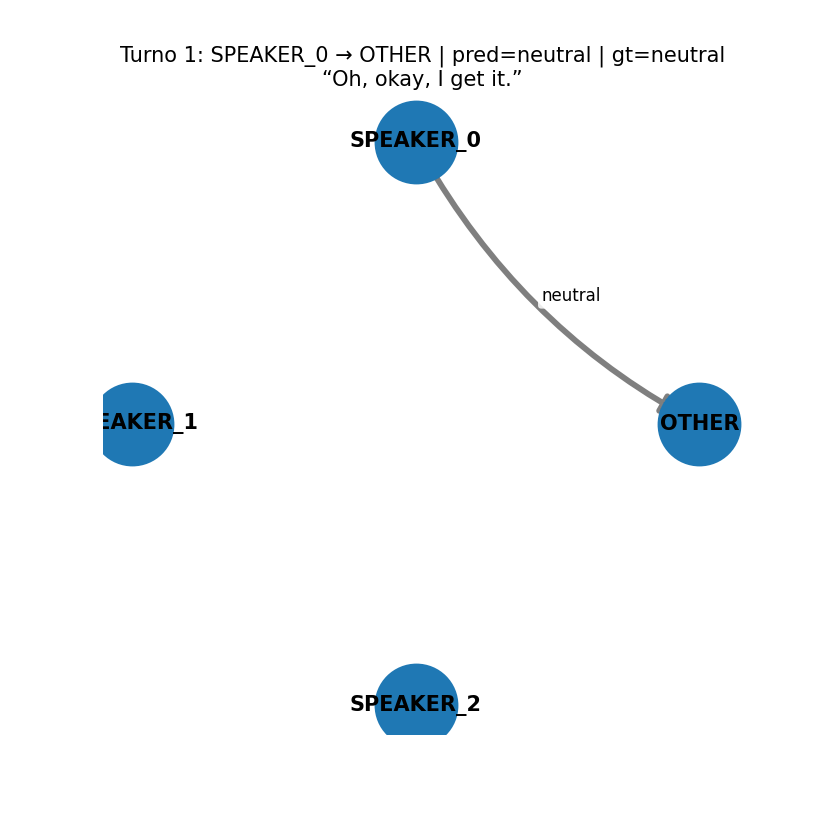

In [17]:
# ====== EJECUCIÓN ======
# Elige split y dialogue_id (si no pones ID, se elige uno aleatorio)
SPLIT = "test"  # "train" | "dev" | "test"
df = {"train": train_df, "dev": dev_df, "test": test_df}[SPLIT]

DIALOGUE_ID = 3  # ej: 110; o deja None para aleatorio

if DIALOGUE_ID is None:
    DIALOGUE_ID = int(df["dialogue_id"].sample(1, random_state=SEED).iloc[0])

print("Usando dialogue_id =", DIALOGUE_ID, "en split =", SPLIT)

rows = build_dialogue_rows(df, DIALOGUE_ID, infer_target_from_prev=True, default_target="OTHER")
classified = classify_dialogue_rows(rows)

gif_path = dialogue_to_gif(classified, out_gif_path=f"emotion_graph_{SPLIT}_{DIALOGUE_ID}.gif", fps=0.5)
print("GIF generado:", gif_path)

display(Image(filename=gif_path))
